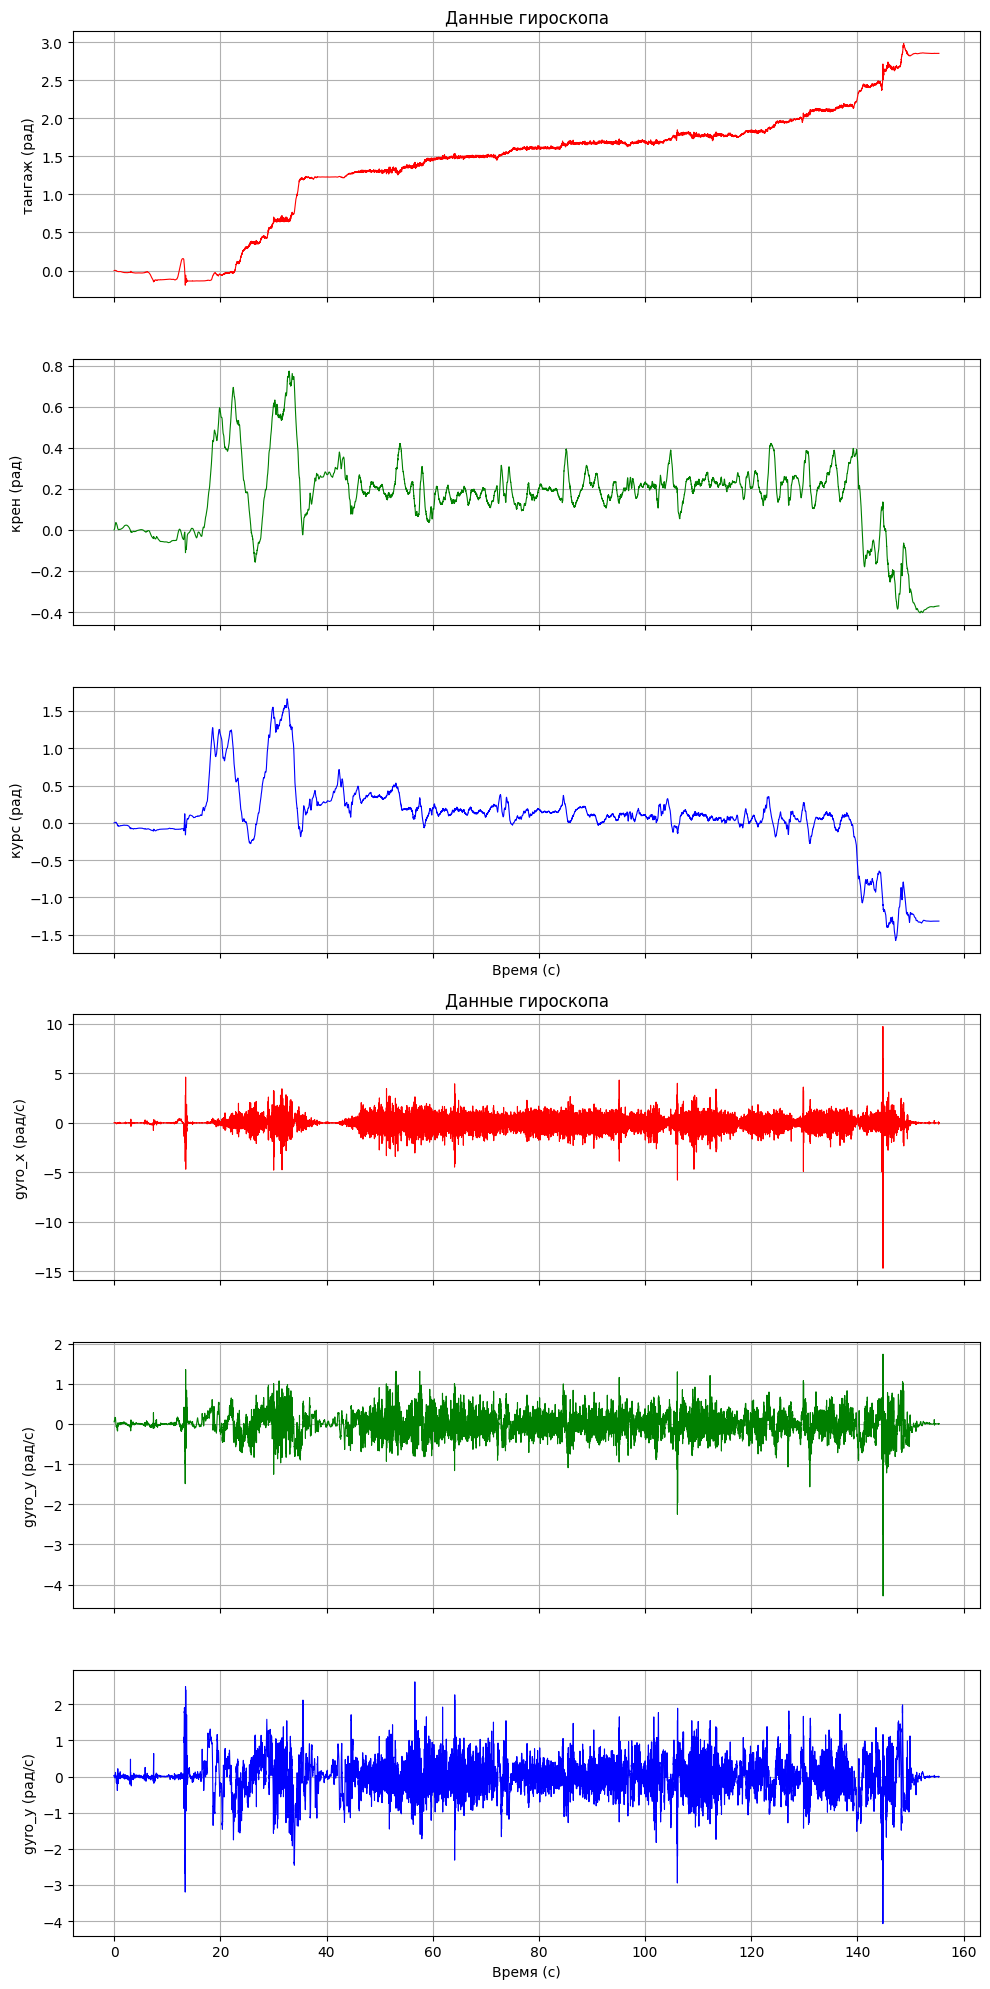

In [175]:
from matplotlib import pyplot as plt
import csv
from math import *
from scipy.integrate import quad, dblquad
import numpy as np
import random


def read_csv_gyro(fname):
    time = []
    x = []
    y = []
    z = []
    init = False
    t0 = 0
    with open(fname, newline = '') as csvfile:
        datareader = csv.reader(csvfile)
        for row in datareader:
            if (len(row)>=4):
                if init:
                    if t0 == 0:
                        t0 = float(row[0])
                    time.append((float(row[0])-t0)/10e8)
                    z.append(float(row[2]))
                    y.append(float(row[3]))
                    x.append(float(row[4]))
                else:
                    init=True
    return time, x, y, z

def integral(t, x0):
    x = [0]
    for i in range(1, len(t)):
        dt = t[i] - t[i-1]
        x.append(x[i-1] + x0[i]*dt)
    return x

def derivative(t, x0):
    x = [0]
    for i in range(1, len(t)):
        dt = t[i] - t[i-1]
        x.append((x0[i] - x0[i-1])/dt)
    return x
    

time, gyro_x, gyro_y, gyro_z = read_csv_gyro("C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\9-2026-10-03_13-22-24\\Gyroscope.csv")
#time, gyro_x, gyro_y, gyro_z = read_csv_gyro("C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\2026-10-03_12-49-46\\Gyroscope.csv")


heading = integral(time, gyro_z)
roll = integral(time, gyro_y)
pitch = integral(time, gyro_x)

fig, axs = plt.subplots(6, 1, figsize=(10, 20), sharex=True)

# График X
axs[0].plot(time, pitch, color='red', linewidth=0.8)
axs[0].set_ylabel('тангаж (рад)')
axs[0].grid(True)
axs[0].set_title('Данные гироскопа')

# График Y
axs[1].plot(time, roll, color='green', linewidth=0.8)
axs[1].set_ylabel('крен (рад)')
axs[1].grid(True)

# График Z
axs[2].plot(time, heading, color='blue', linewidth=0.8)
axs[2].set_ylabel('курс (рад)')
axs[2].set_xlabel('Время (с)')
axs[2].grid(True)

# График X
axs[3].plot(time, gyro_x, color='red', linewidth=0.8)
axs[3].set_ylabel('gyro_x (рад/с)')
axs[3].grid(True)
axs[3].set_title('Данные гироскопа')

# График Y
axs[4].plot(time, gyro_y, color='green', linewidth=0.8)
axs[4].set_ylabel('gyro_y (рад/с)')
axs[4].grid(True)

# График Z
axs[5].plot(time, gyro_z, color='blue', linewidth=0.8)
axs[5].set_ylabel('gyro_y (рад/с)')
axs[5].set_xlabel('Время (с)')
axs[5].grid(True)

# Автоматически подгоняем отступы, чтобы подписи не перекрывались
plt.tight_layout()

# Отображаем все графики в одном окне
plt.show()

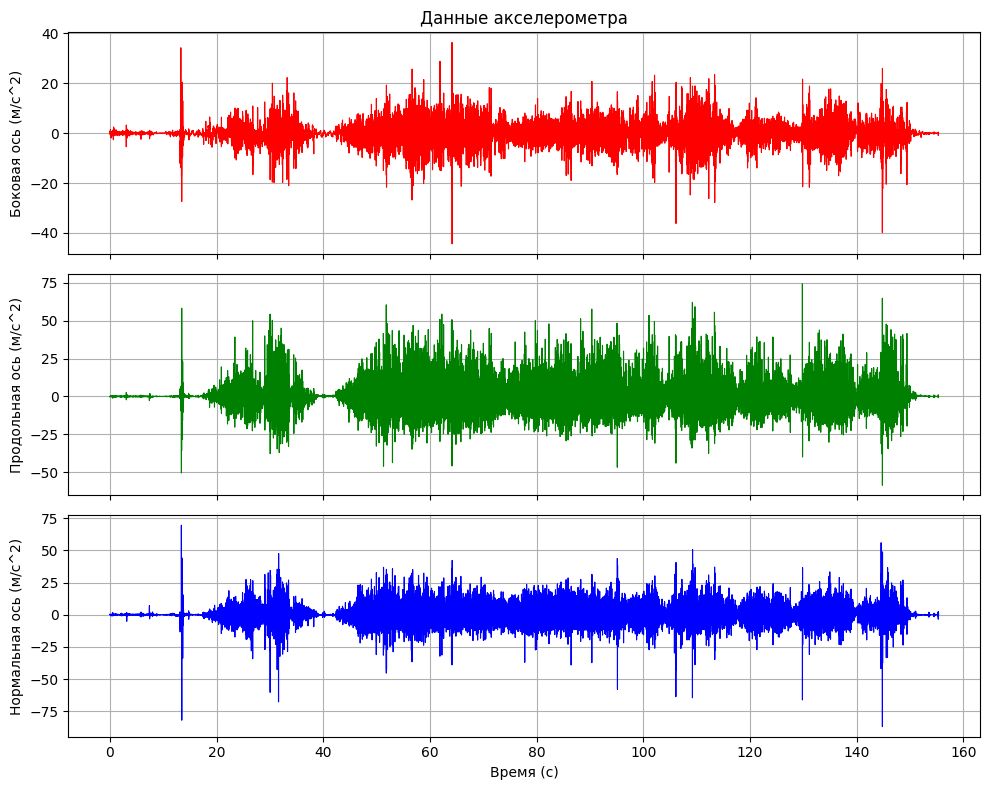

In [176]:
def read_csv_acc(fname):
    time = []
    x = []
    y = []
    z = []
    altitude = []
    longitude = []
    latitude = []
    init = False
    t0 = 0
    with open(fname, newline = '') as csvfile:
        datareader = csv.reader(csvfile)
        for row in datareader:
            if (len(row)>=4):
                if init:
                    if t0 == 0:
                        t0 = float(row[0])
                    time.append((float(row[0])-t0)/10e8)
                    z.append(float(row[2]))
                    y.append(float(row[3]))
                    x.append(float(row[4]))
                else:
                    init=True
    return time, x, y, z

time, acc_x, acc_y, acc_z = read_csv_acc('C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\9-2026-10-03_13-22-24\\Accelerometer.csv')
#time, acc_x, acc_y, acc_z = read_csv_acc("C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\2026-10-03_12-49-46\\Accelerometer.csv")

fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# График X
axs[0].plot(time, acc_x, color='red', linewidth=0.8)
axs[0].set_ylabel('Боковая ось (м/с^2)')
axs[0].grid(True)
axs[0].set_title('Данные акселерометра')

# График Y
axs[1].plot(time, acc_y, color='green', linewidth=0.8)
axs[1].set_ylabel('Продольная ось (м/с^2)')
axs[1].grid(True)

# График Z
axs[2].plot(time, acc_z, color='blue', linewidth=0.8)
axs[2].set_ylabel('Нормальная ось (м/с^2)')
axs[2].set_xlabel('Время (с)')
axs[2].grid(True)

# Автоматически подгоняем отступы, чтобы подписи не перекрывались
plt.tight_layout()

# Отображаем все графики в одном окне
plt.show()

15999


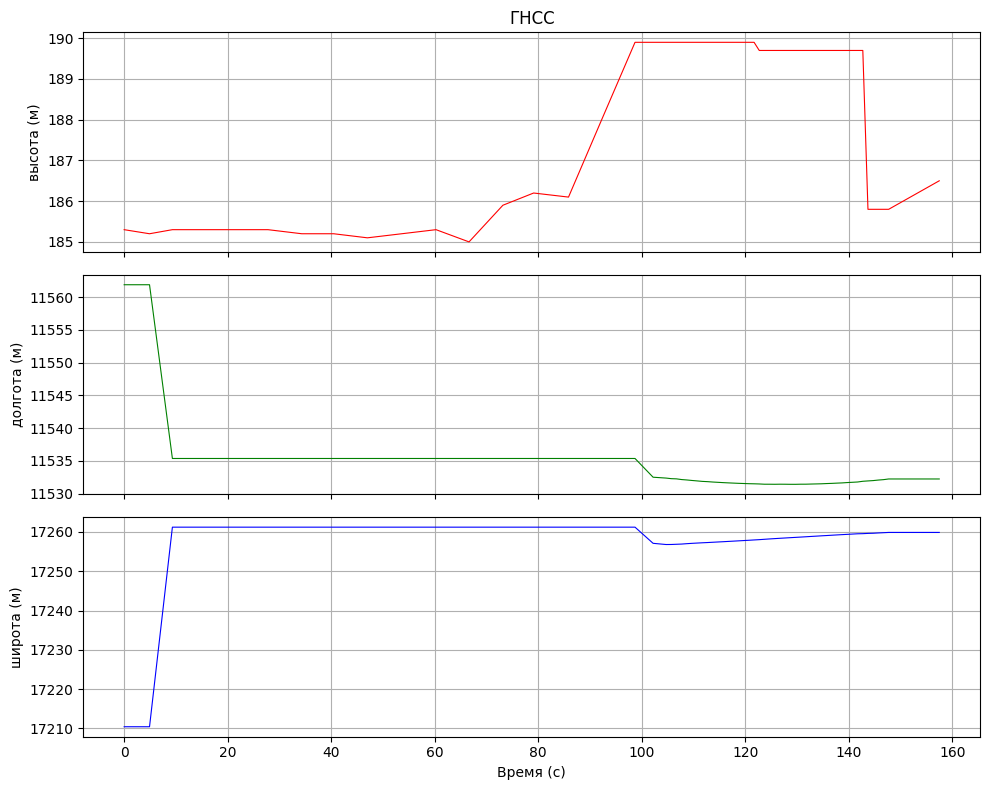

In [177]:
def read_csv_gnss(fname):
    time = []
    altitude = []
    longitude = []
    latitude = []
    init = False
    t0 = 0
    with open(fname, newline = '') as csvfile:
        datareader = csv.reader(csvfile)
        for row in datareader:
            if (len(row)>=4):
                if init:
                    if t0 == 0:
                        t0 = float(row[0])
                    time.append((float(row[0])-t0)/10e8)
                    altitude.append(float(row[8]))
                    longitude.append(float(row[9])*111000/360)
                    latitude.append(float(row[10])*111000/360)
                else:
                    init=True
    return time, altitude, longitude, latitude

time_gnss, altitude, longitude, latitude = read_csv_gnss('C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\9-2026-10-03_13-22-24\\Location.csv')
#time_gnss, altitude, longitude, latitude = read_csv_gnss("C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\2026-10-03_12-49-46\\Location.csv")

print(len(time))

fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# График X
axs[0].plot(time_gnss, altitude, color='red', linewidth=0.8)
axs[0].set_ylabel('высота (м)')
axs[0].grid(True)
axs[0].set_title('ГНСС')

# График Y
axs[1].plot(time_gnss, longitude, color='green', linewidth=0.8)
axs[1].set_ylabel('долгота (м)')
axs[1].grid(True)

# График Z
axs[2].plot(time_gnss, latitude, color='blue', linewidth=0.8)
axs[2].set_ylabel('широта (м)')
axs[2].set_xlabel('Время (с)')
axs[2].grid(True)

# Автоматически подгоняем отступы, чтобы подписи не перекрывались
plt.tight_layout()

# Отображаем все графики в одном окне
plt.show()

15999
15999


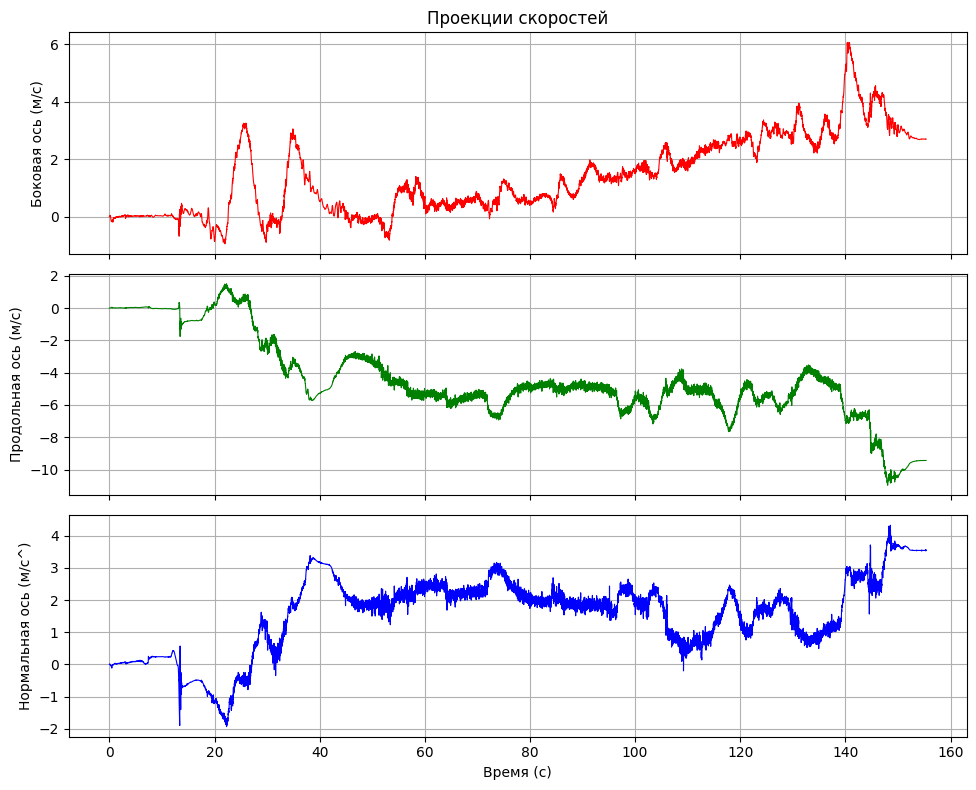

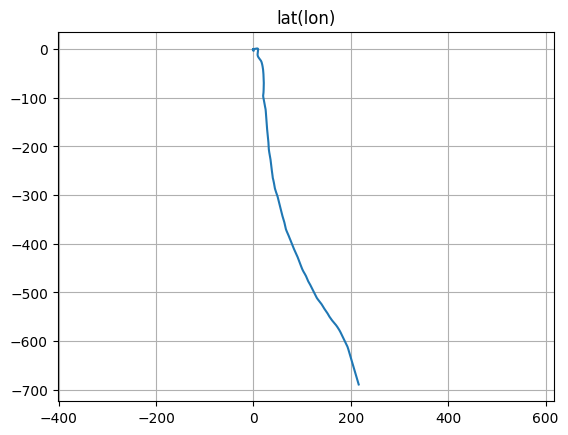

In [178]:
V_prod = integral(time, acc_y)
V_bok = integral(time, acc_x)
V_norm = integral(time, acc_z)

print(len(time))
print(len(V_bok))

fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
# График X
axs[0].plot(time, V_bok, color='red', linewidth=0.8)
axs[0].set_ylabel('Боковая ось (м/с)')
axs[0].grid(True)
axs[0].set_title('Проекции скоростей')

# График Y
axs[1].plot(time, V_prod, color='green', linewidth=0.8)
axs[1].set_ylabel('Продольная ось (м/с)')
axs[1].grid(True)

# График Z
axs[2].plot(time, V_norm, color='blue', linewidth=0.8)
axs[2].set_ylabel('Нормальная ось (м/с^)')
axs[2].set_xlabel('Время (с)')
axs[2].grid(True)

# Автоматически подгоняем отступы, чтобы подписи не перекрывались
plt.tight_layout()

# Отображаем все графики в одном окне
plt.show()

lon = integral(time, V_bok)
lat = integral(time, V_prod)
plt.plot(lon, lat)
plt.grid(True)
plt.title('lat(lon)')
plt.axis('equal')
plt.show()

C:\Users\o4enn\AppData\Local\Temp\ipykernel_27280\1689027617.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


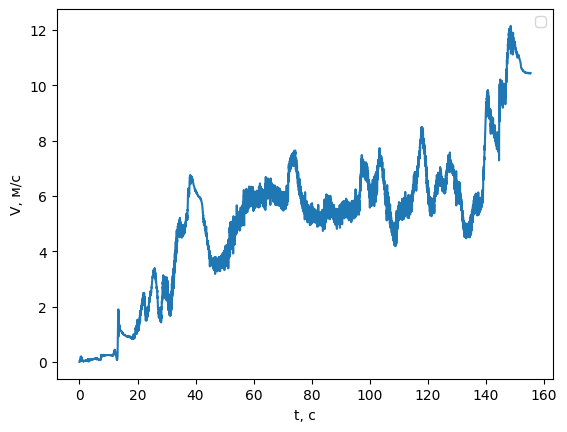

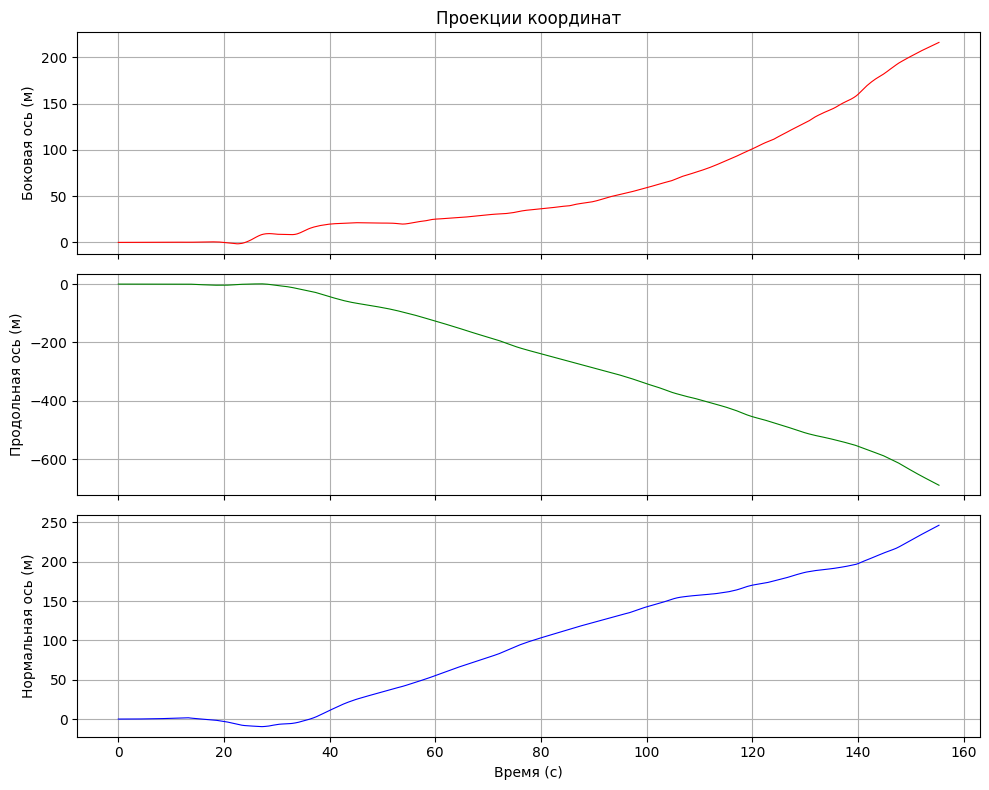

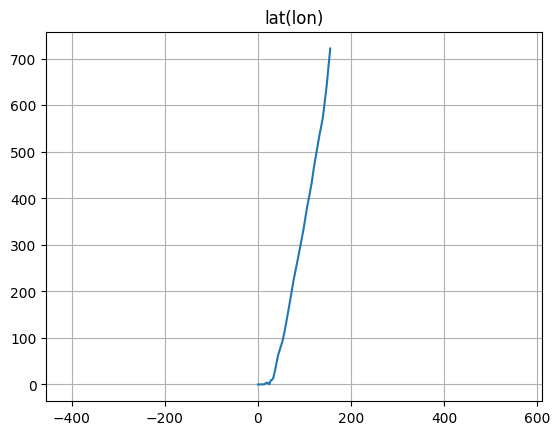

In [179]:
V = []
for i in range(len(V_bok)):
    V.append(sqrt(V_bok[i]**2+V_norm[i]**2+V_prod[i]**2))

plt.plot(time, V)
plt.xlabel('t, c')
plt.ylabel('V, м/с')
plt.legend()
plt.show()

y = integral(time, V_prod)
x = integral(time, V_bok)
z = integral(time, V_norm)

summm = []
for i in range(len(V_bok)):
    summm.append(sqrt(x[i]**2+y[i]**2))

fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
# График X
axs[0].plot(time, x, color='red', linewidth=0.8)
axs[0].set_ylabel('Боковая ось (м)')
axs[0].grid(True)
axs[0].set_title('Проекции координат')

# График Y
axs[1].plot(time, y, color='green', linewidth=0.8)
axs[1].set_ylabel('Продольная ось (м)')
axs[1].grid(True)

# График Z
axs[2].plot(time, z, color='blue', linewidth=0.8)
axs[2].set_ylabel('Нормальная ось (м)')
axs[2].set_xlabel('Время (с)')
axs[2].grid(True)

# Автоматически подгоняем отступы, чтобы подписи не перекрывались
plt.tight_layout()

# Отображаем все графики в одном окне
plt.show()

plt.plot(time, summm)
plt.grid(True)
plt.title('lat(lon)')
plt.axis('equal')
plt.show()

In [180]:
dr_grs = 0.01*pi/180/3600 #rad/s
shum_grs = dr_grs*0.01*(random.random()-0.5)*2 #rad/s
dr_acc = 8*10**(-3) #m/s^2
shum_acc = dr_acc*0.01*(random.random()-0.5)*2 #m/s^2

x1, x2 = 8, 8 #m - ошибки определения координат БИНС, связанные с ошибками определения долготы и широты, соответственно
x3, x4 = 0.15, 0.15 #m/s – ошибки в определении скорости изменения координат БИНС, связанные с ошибками определения восточной и северной составляющими путевой скорости (проекции путевой скорости на оси НЗСК)
gamma = 0.1*pi/180 #rad
alfa, betta = 0.01*pi/180, 0.01*pi/180 #rad


speed_GNSS_sh = 0.1 #m/s

a = 6378245 #м, большая полуось в эллипсоиде Красовского
b = 6356863 #м, малая полуось в эллипсоиде Красовского
eks = 0.00335232987
w_sh = 1.53809*10**(-6)
print(w_sh)

R_e = 6371000 #Средний радиус Земли в метрах

#Начальная погрешность определения местоположения
X1 = [x1]
X2 = [x2]
X3 = [x3]
X4 = [x4]
time_model = [0.4]
p1_list = [a * (1 - eks**2)/(sqrt(1 - eks**2 * sin(latitude[0])**2))**3 + altitude[0]]
p2_list = [a/sqrt(1 - eks**2 * sin(latitude[0])**2) + altitude[0]]

'''Это из курсача Петухова'''
koord_GNSS_sh1 = 4/(p2_list[0]*cos(latitude[0])) #m
koord_GNSS_sh2 = 4/p1_list[0] #m
'''Это из курсача Петухова'''

X_0 = np.array([x1, x2, x3, x4, alfa, betta, gamma, dr_grs, dr_grs, dr_grs, dr_acc, dr_acc, dr_acc])
X = X_0

'''Для модели измерений'''
Z_lyamda, Z_fi, Z_Ve, Z_Vn = [], [], [], []

V = np.array([koord_GNSS_sh1, koord_GNSS_sh2, speed_GNSS_sh, speed_GNSS_sh]) #Вектор шумов системы 

'''Для ОФК'''


#print(f'R = {R}')
E = np.eye(13)

X_kr_pred = X_0

P_pred = np.diag([x1**2, x2**2, x3**2, x4**2, alfa**2, betta**2, gamma**2, dr_grs**2, dr_grs**2, dr_grs**2, dr_acc**2, dr_acc**2, dr_acc**2])

X_kr_list1 = [X_0[0]]
X_kr_list2 = [X_0[1]]
X_kr_list3 = [X_0[2]]
X_kr_list4 = [X_0[3]]
X_kr_list_alfa = [X_0[4]]
X_kr_list_beta = [X_0[5]]
X_kr_list_gamma = [X_0[6]]

min_SKO1 = [-3*sqrt(P_pred[0][0])]
min_SKO2 = [-3*sqrt(P_pred[1][1])]
min_SKO3 = [-3*sqrt(P_pred[2][2])]
min_SKO4 = [-3*sqrt(P_pred[3][3])]
min_SKO5 = [-3*sqrt(P_pred[4][4])]
min_SKO6 = [-3*sqrt(P_pred[5][5])]
min_SKO7 = [-3*sqrt(P_pred[6][6])]

SKO1 = [3*sqrt(P_pred[0][0])]
SKO2 = [3*sqrt(P_pred[1][1])]
SKO3 = [3*sqrt(P_pred[2][2])]
SKO4 = [3*sqrt(P_pred[3][3])]
SKO5 = [3*sqrt(P_pred[4][4])]
SKO6 = [3*sqrt(P_pred[5][5])]
SKO7 = [3*sqrt(P_pred[6][6])]

1.5380899999999999e-06


In [181]:
'''Эта хрень вычисляется по данным от ГНСС-модуля'''
Vh_gnss = derivative(time_gnss, altitude)
Ve_gnss = derivative(time_gnss, longitude)
Vn_gnss = derivative(time_gnss, latitude)

Vh = V_prod
Ve = V_bok
Vn = V_norm


print(len(longitude))
print(len(latitude))
print(len(Ve))
print(len(Vn))

i = 1

for t in range(1, len(time)):
    shag_vrem = time[t] - time[t-1]
    #shag_vrem = 0.1
    time_model.append(time[t])

    if (t%289!=0):    # *111000/360 - перевод из градусов в метры   
        p1_list.append(a * (1 - eks**2)/(sqrt(1 - eks**2 * sin(latitude[i])**2))**3 + altitude[i])
        p2_list.append(a/sqrt(1 - eks**2 * sin(latitude[i])**2) + altitude[i])
    else:
        i+=1
        p1_list.append(a * (1 - eks**2)/(sqrt(1 - eks**2 * sin(latitude[i])**2))**3 + altitude[i])
        p2_list.append(a/sqrt(1 - eks**2 * sin(latitude[i])**2) + altitude[i])

    '''delta_lyamda = X[0]/(p2_list[t] * cos(latitude[t])) #ошибка определения долготы
    delta_fi = X[1]/p1_list[t] #ошибка определения широты '''
    
    #Матрица перехода из связанной СК в нормальную
    c11 = cos(heading[t])*cos(pitch[t])
    c12 = sin(heading[t])*sin(roll[t]) - cos(heading[t])*sin(pitch[t])*cos(roll[t])
    c13 = sin(heading[t])*cos(roll[t]) + cos(heading[t])*sin(pitch[t])*sin(roll[t])
    c21 = sin(pitch[t])
    c22 = cos(pitch[t])*cos(roll[t])
    c23 = -cos(pitch[t])*sin(roll[t])
    c31 = -sin(heading[t])*cos(pitch[t])
    c32 = cos(heading[t])*sin(roll[t]) + sin(heading[t])*sin(pitch[t])*cos(roll[t])
    c33 = cos(heading[t])*cos(roll[t]) - sin(heading[t])*sin(pitch[t])*sin(roll[t])
    C = np.array([[c11, c12, c13], 
                  [c21, c22, c23], 
                  [c31, c32, c33]])


    gyro = np.array([gyro_y[t], gyro_x[t], gyro_z[t]])
    Omega = C @ gyro

    #print(f'omega = {Omega}')
    
    '''delta_Ve = X[2] - (Vh[t]/p2_list[t] + Omega[0]*tan(latitude[t]))*X[0] - Omega[1]*X[1] #ошибка определения восточной проекции путевой скорости
    delta_VN = X[3] - Vh[t]/p1_list[t] * X[0] #ошибка определения северной проекции путевой скорости'''

    '''print(delta_lyamda)
    print(delta_fi)
    print(delta_Ve)
    print(delta_VN)
    print('-------')'''
  

    acc = np.array([acc_x[t], acc_y[t], acc_z[t]])
    n = C @ acc
  
    #Если будут ошибки, перепроверить тут

    F = np.array([
        [0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [-w_sh**2, 0, 0, 0, 0, n[1], 0, 0, 0, 0, C[0][0], C[0][1], C[0][2]],
        [0, -w_sh**2, 0, 0, -n[1], 0, n[0], 0, 0, 0, C[1][0], C[1][1], C[1][2]],
        [0, 0, 0, 0, 0, 0, 0, C[0][0], C[0][1], C[0][2], 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, C[1][0], C[1][1], C[1][2], 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, C[2][0], C[2][1], C[2][2], 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
        ])
    
    W = np.array([shum_grs, shum_grs, shum_grs, shum_acc, shum_acc, shum_acc])

    G = np.array([
        [0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0],
        [0, 0, 0, C[0][0], C[0][1], C[0][2]],
        [0, 0, 0, C[1][0], C[1][1], C[1][2]],
        [C[0][0], C[0][1], C[0][2], 0, 0, 0],
        [C[1][0], C[1][1], C[1][2], 0, 0, 0],
        [C[2][0], C[2][1], C[2][2], 0, 0, 0],
        [0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0]
        ])
    
    Xtoch = F @ X + G @ W #Нашли вектор Х с точкой, теперь нужно проинтегрировать Эйлером и записать результаты в списки
    #print (Xtoch)
    #print(X)
    X = X + Xtoch * shag_vrem
    X1.append(X[0].tolist() - X_0[0])
    X2.append(X[1].tolist() - X_0[1])
    X3.append(X[2].tolist() - X_0[2])
    X4.append(X[3].tolist() - X_0[3])

    lyamda_BINS = X1[t]
    fi_BINS = X2[t]
    Ve_BINS = X3[t]
    Vn_BINS = X4[t]

    lyamda_GNSS = (longitude[i])
    fi_GNSS = (latitude[i]) 
    Ve_GNSS = (Ve_gnss[i])
    Vn_GNSS = (Vn_gnss[i])

    '''if (t%295==0):
        Z_matr = np.array([lyamda_BINS-lyamda_GNSS, fi_BINS-fi_GNSS, Ve_BINS-Ve_GNSS, Vn_BINS-Vn_GNSS]) #Вектор измерений
    else:
        Z_matr = np.array([lyamda_BINS-0, fi_BINS-0, Ve_BINS-0, Vn_BINS-0]) #Вектор измерений'''

    Z_matr = np.array([lyamda_BINS-lyamda_GNSS, fi_BINS-fi_GNSS, Ve_BINS-Ve_GNSS, Vn_BINS-Vn_GNSS]) #Вектор измерений

    H = np.array([  #Матрица связи вектора состояния и вектора измерений
        [1/(p2_list[t]*cos(latitude[i]*pi/180)), 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 1/p1_list[t], 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [-(Vh[i]/p2_list[t] + Omega[0]*tan(latitude[i]*pi/180)), -Omega[1], 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [-Vh[i]/p1_list[t], 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
        ])
    
    '''АЛГОРИТM ОФК'''
    Ef_rus = E + F*shag_vrem
    Ge_rus = G*shag_vrem

    R = np.diag([koord_GNSS_sh1**2/shag_vrem, koord_GNSS_sh2**2/shag_vrem, speed_GNSS_sh**2/shag_vrem, speed_GNSS_sh**2/shag_vrem]) #Матрица интенсивности шумов системы
    Q = np.diag([shum_grs**2/shag_vrem, shum_grs**2/shag_vrem, shum_grs**2/shag_vrem, shum_acc**2/shag_vrem, shum_acc**2/shag_vrem, shum_acc**2/shag_vrem]) #матрица интенсивности шумов системы

    S = Ef_rus @ P_pred @ Ef_rus.T + Ge_rus @ (Q) @ Ge_rus.T #Расчет априорной матрицы ковариации

    #Считаем Калмановские коэффициенты усиления

    K = S @ H.T @ np.linalg.inv(H @ S @ H.T + (R))

    P_new = (E - K @ H) @ S #Расчет апостериорной матрицы ковариации

    X_kr = Ef_rus @ X_kr_pred + K @ (Z_matr - H @ Ef_rus @ X_kr_pred)

    X_kr_list1.append(X_kr[0])
    X_kr_list2.append(X_kr[1])
    X_kr_list3.append(X_kr[2])
    X_kr_list4.append(X_kr[3])
    X_kr_list_alfa.append(X_kr[4])
    X_kr_list_beta.append(X_kr[5])
    X_kr_list_gamma.append(X_kr[6])
    SKO = np.diag([sqrt(P_pred[0][0]), sqrt(P_pred[1][1]), sqrt(P_pred[2][2]), sqrt(P_pred[3][3]), sqrt(P_pred[4][4]), sqrt(P_pred[5][5]), sqrt(P_pred[6][6]), 
               sqrt(P_pred[7][7]), sqrt(P_pred[8][8]), sqrt(P_pred[9][9]), sqrt(P_pred[10][10]), sqrt(P_pred[11][11]), sqrt(P_pred[12][12])])

    P_pred = P_new
    
    #print(SKO)
    X_kr_pred = X_kr

    min_SKO1.append(-3*SKO[0][0])
    min_SKO2.append(-3*SKO[1][1])
    min_SKO3.append(-3*SKO[2][2])
    min_SKO4.append(-3*SKO[3][3])
    min_SKO5.append(-3*SKO[4][4])
    min_SKO6.append(-3*SKO[5][5])
    min_SKO7.append(-3*SKO[6][6])

    SKO1.append(3*SKO[0][0])
    SKO2.append(3*SKO[1][1])
    SKO3.append(3*SKO[2][2])
    SKO4.append(3*SKO[3][3])
    SKO5.append(3*SKO[4][4])
    SKO6.append(3*SKO[5][5])
    SKO7.append(3*SKO[6][6])

print(SKO1[0])


63
63
15999
15999
24.0


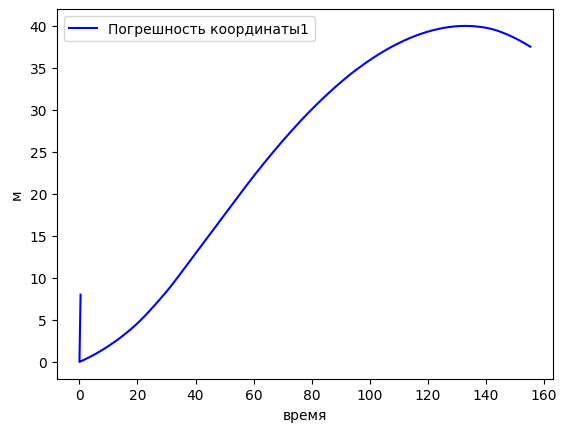

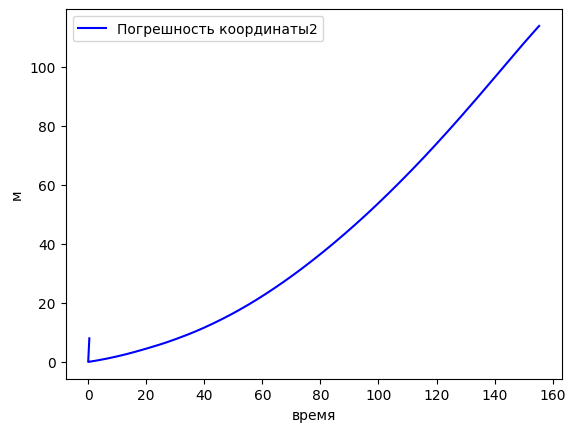

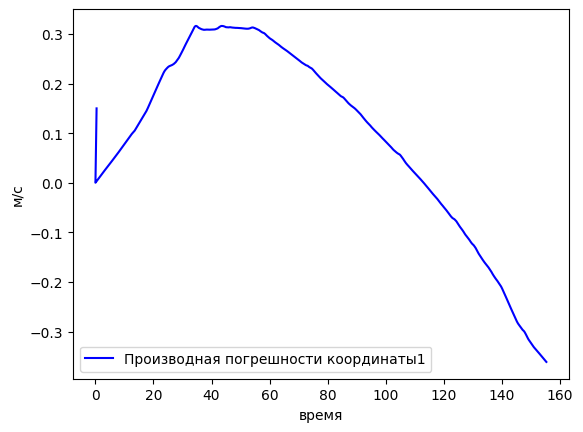

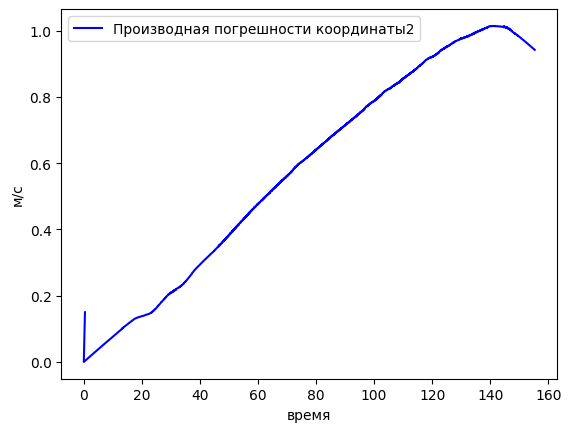

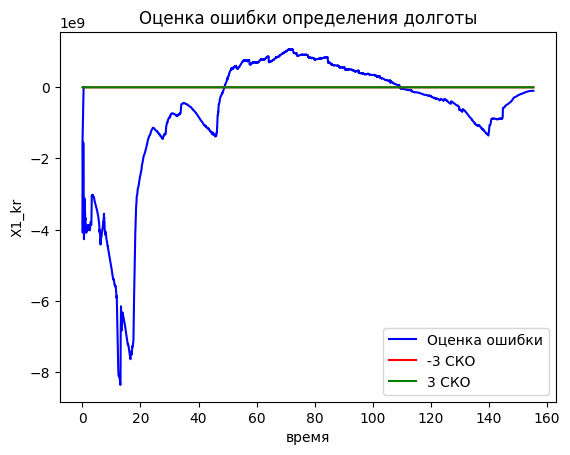

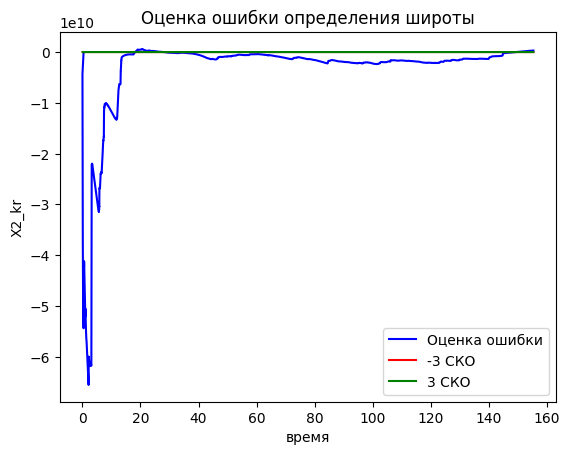

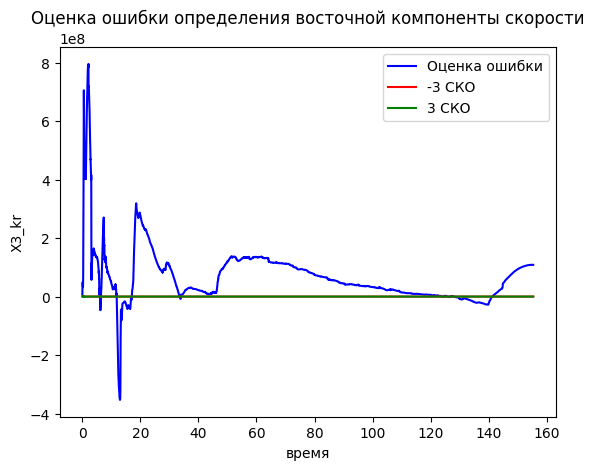

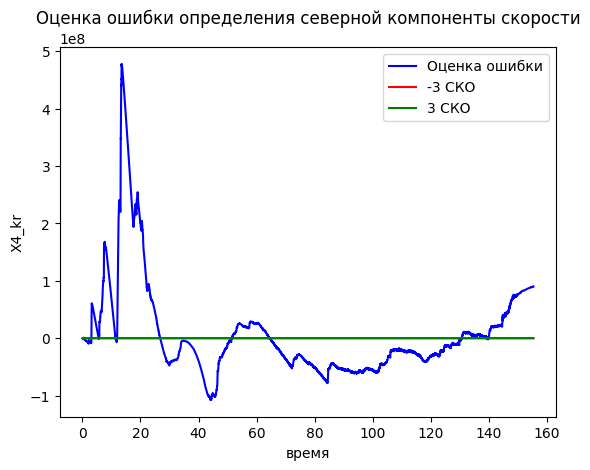

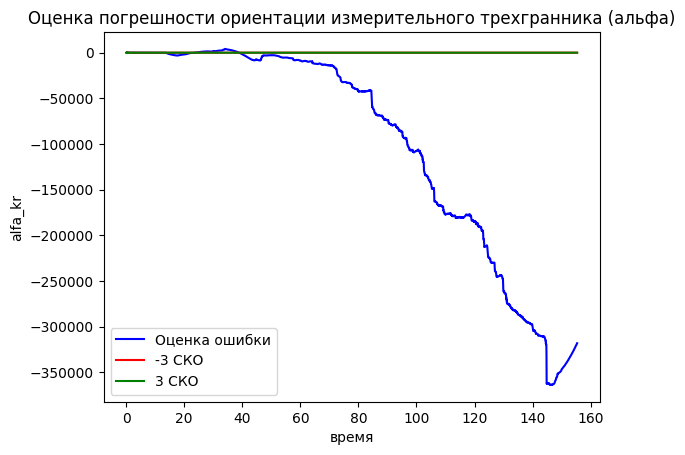

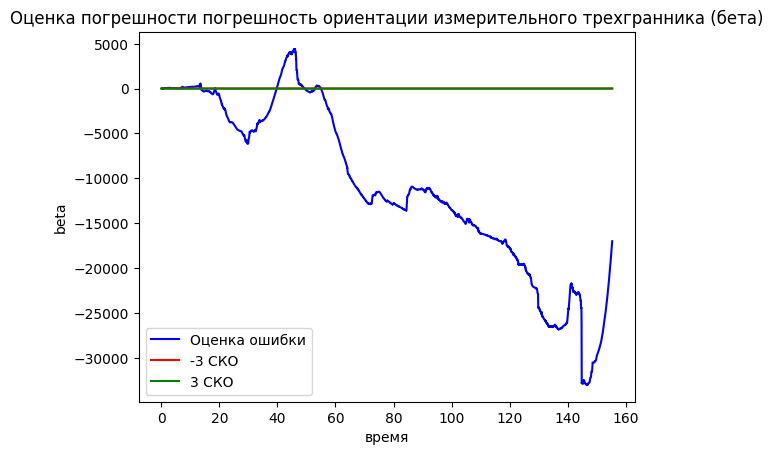

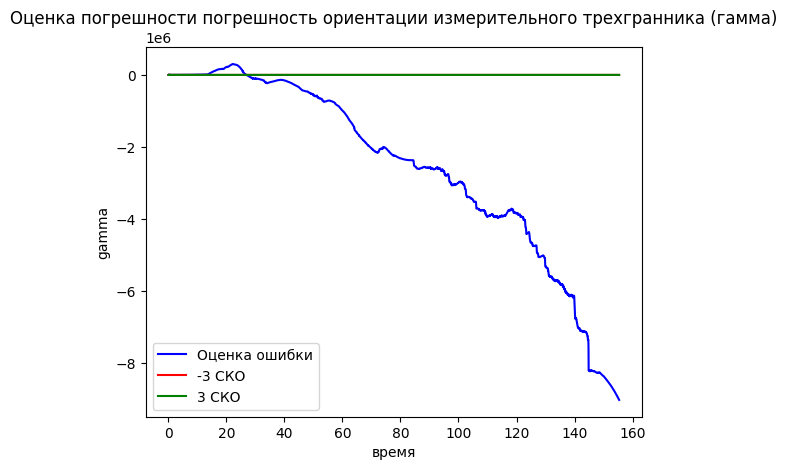

In [182]:

# Графики погрешностей
plt.plot(time_model, X1, c='b', label='Погрешность координаты1')
plt.xlabel('время')
plt.ylabel('м')
plt.legend() 
plt.show()

plt.plot(time_model, X2, c='b', label='Погрешность координаты2')
plt.xlabel('время')
plt.ylabel('м')
plt.legend()
plt.show()

plt.plot(time_model, X3, c='b', label='Производная погрешности координаты1')
plt.xlabel('время')
plt.ylabel('м/с')
plt.legend()
plt.show()

plt.plot(time_model, X4, c='b', label='Производная погрешности координаты2')
plt.xlabel('время')
plt.ylabel('м/с')
plt.legend()
plt.show()

'''Итоговые графики'''

plt.figure()
plt.plot(time_model, X_kr_list1, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO1, label='-3 СКО', c='r')  # Добавляем метку для СКО
plt.plot(time_model, SKO1, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('X1_kr')
plt.title('Оценка ошибки определения долготы')
plt.legend(loc='best')  # Автоматическое размещение легенды
plt.show()

plt.plot(time_model, X_kr_list2, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO2, label='-3 СКО', c='r')
plt.plot(time_model, SKO2, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('X2_kr')
plt.title('Оценка ошибки определения широты')
plt.legend()
plt.show()

plt.plot(time_model, X_kr_list3, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO3, label='-3 СКО', c='r')
plt.plot(time_model, SKO3, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('X3_kr')
plt.title('Оценка ошибки определения восточной компоненты скорости')
plt.legend()
plt.show()

plt.plot(time_model, X_kr_list4, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO4, label='-3 СКО', c='r')
plt.plot(time_model, SKO4, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('X4_kr')
plt.title('Оценка ошибки определения северной компоненты скорости')
plt.legend()
plt.show()

# Графики ориентации
plt.plot(time_model, X_kr_list_alfa, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO5, label='-3 СКО', c='r')
plt.plot(time_model, SKO5, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('alfa_kr')
plt.title('Оценка погрешности ориентации измерительного трехгранника (альфа)')
plt.legend()
plt.show()

plt.plot(time_model, X_kr_list_beta, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO6, label='-3 СКО', c='r')
plt.plot(time_model, SKO6, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('beta')
plt.title('Оценка погрешности погрешность ориентации измерительного трехгранника (бета)')
plt.legend()
plt.show()

plt.plot(time_model, X_kr_list_gamma, label='Оценка ошибки', c='b')
plt.plot(time_model, min_SKO7, label='-3 СКО', c='r')
plt.plot(time_model, SKO7, label='3 СКО', c='g')  # Добавляем метку для СКО
plt.xlabel('время')
plt.ylabel('gamma')
plt.title('Оценка погрешности погрешность ориентации измерительного трехгранника (гамма)')
plt.legend()
plt.show()


НИЖЕ ЗАЛУПА ОТ КВЕНА ПО ЧТЕНИЮ ФАЙЛОВ И ПОСТРОЕНИЮ ГРАФИКОВ

In [183]:
'''import csv
from math import pi

# ==========================================
# ФУНКЦИИ ЧТЕНИЯ ДАННЫХ (в стиле вашего кода)
# ==========================================

def read_accelerometer(fname):
    """
    Читает данные акселерометра.
    Формат CSV: time, seconds_elapsed, z, y, x (ускорения в g)
    
    Возвращает списки:
        time_acc        - абсолютное время [s]
        seconds_elapsed - время от начала записи [s]
        ax, ay, az      - ускорения по осям [g]
    """
    time_acc = []
    seconds_elapsed = []
    ax = []  # ускорение по X [g]
    ay = []  # ускорение по Y [g]
    az = []  # ускорение по Z [g]
    
    with open(fname, newline='') as csvfile:
        datareader = csv.reader(csvfile)
        for row in datareader:
            if len(row) >= 5:
                # Пропускаем заголовок, если он есть
                try:
                    time_acc.append(float(row[0]))
                    seconds_elapsed.append(float(row[1]))
                    az.append(float(row[2]))  # z
                    ay.append(float(row[3]))  # y
                    ax.append(float(row[4]))  # x
                except ValueError:
                    # Строка заголовка или некорректные данные - пропускаем
                    continue
    
    print(f"[Акселерометр] Прочитано {len(time_acc)} измерений")
    print(f"  Диапазон времени: {seconds_elapsed[0]:.2f} - {seconds_elapsed[-1]:.2f} сек")
    
    return time_acc, seconds_elapsed, ax, ay, az


def read_gyroscope(fname):
    """
    Читает данные гироскопа.
    Формат CSV: time, seconds_elapsed, z, y, x (угловые скорости в deg/s)
    
    Возвращает списки:
        time_grs        - абсолютное время [s]
        seconds_elapsed - время от начала записи [s]
        wx, wy, wz      - угловые скорости по осям [deg/s]
    """
    time_grs = []
    seconds_elapsed = []
    wx = []  # угловая скорость вокруг X [deg/s]
    wy = []  # угловая скорость вокруг Y [deg/s]
    wz = []  # угловая скорость вокруг Z [deg/s]
    
    with open(fname, newline='') as csvfile:
        datareader = csv.reader(csvfile)
        for row in datareader:
            if len(row) >= 5:
                try:
                    time_grs.append(float(row[0]))
                    seconds_elapsed.append(float(row[1]))
                    wz.append(float(row[2]))  # z
                    wy.append(float(row[3]))  # y
                    wx.append(float(row[4]))  # x
                except ValueError:
                    continue
    
    print(f"[Гироскоп] Прочитано {len(time_grs)} измерений")
    print(f"  Диапазон времени: {seconds_elapsed[0]:.2f} - {seconds_elapsed[-1]:.2f} сек")
    
    return time_grs, seconds_elapsed, wx, wy, wz


def read_location(fname):
    """
    Читает данные GPS (Location).
    Формат CSV: time, seconds_elapsed, bearingAccuracy, speedAccuracy, 
                verticalAccuracy, horizontalAccuracy, speed, bearing, 
                altitude, longitude, latitude
    
    Возвращает списки:
        time_loc           - абсолютное время [s]
        seconds_elapsed    - время от начала записи [s]
        bearingAccuracy    - точность пеленга [deg]
        speedAccuracy      - точность скорости [m/s]
        verticalAccuracy   - точность высоты [m]
        horizontalAccuracy - точность горизонтали [m]
        speed              - скорость [m/s]
        bearing            - пеленг [deg]
        altitude           - высота [m]
        longitude          - долгота [deg]
        latitude           - широта [deg]
    """
    time_loc = []
    seconds_elapsed = []
    bearingAccuracy = []
    speedAccuracy = []
    verticalAccuracy = []
    horizontalAccuracy = []
    speed = []
    bearing = []
    altitude = []
    longitude = []
    latitude = []
    
    with open(fname, newline='') as csvfile:
        datareader = csv.reader(csvfile)
        for row in datareader:
            if len(row) >= 11:
                try:
                    time_loc.append(float(row[0]))
                    seconds_elapsed.append(float(row[1]))
                    bearingAccuracy.append(float(row[2]))
                    speedAccuracy.append(float(row[3]))
                    verticalAccuracy.append(float(row[4]))
                    horizontalAccuracy.append(float(row[5]))
                    speed.append(float(row[6]))
                    bearing.append(float(row[7]))
                    altitude.append(float(row[8]))
                    longitude.append(float(row[9]))
                    latitude.append(float(row[10]))
                except ValueError:
                    continue
    
    print(f"[GPS] Прочитано {len(time_loc)} измерений")
    print(f"  Диапазон времени: {seconds_elapsed[0]:.2f} - {seconds_elapsed[-1]:.2f} сек")
    print(f"  Средняя точность горизонтали: {sum(horizontalAccuracy)/len(horizontalAccuracy):.2f} м")
    
    return (time_loc, seconds_elapsed, bearingAccuracy, speedAccuracy, 
            verticalAccuracy, horizontalAccuracy, speed, bearing, 
            altitude, longitude, latitude)


# ==========================================
# ПРИМЕР ИСПОЛЬЗОВАНИЯ
# ==========================================

if __name__ == '__main__':
    # Пути к файлам (замените на свои)
    ACCEL_FILE = r"C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\2026-10-03_12-49-46\\Accelerometer.csv"
    GYRO_FILE = r"C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\2026-10-03_12-49-46\\Gyroscope.csv"
    LOCATION_FILE = r"C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\2026-10-03_12-49-46\\Location.csv"
    
    print("=" * 60)
    print("ЧТЕНИЕ ДАННЫХ С ДАТЧИКОВ")
    print("=" * 60)
    
    # Читаем данные
    time_acc, sec_acc, ax, ay, az = read_accelerometer(ACCEL_FILE)
    print()
    
    time_grs, sec_grs, wx, wy, wz = read_gyroscope(GYRO_FILE)
    print()
    
    (time_loc, sec_loc, bearingAcc, speedAcc, vertAcc, 
     horizAcc, speed, bearing, altitude, longitude, latitude) = read_location(LOCATION_FILE)
    
    print("\n" + "=" * 60)
    print("СВОДКА")
    print("=" * 60)
    print(f"Акселерометр: {len(time_acc)} точек")
    print(f"Гироскоп:     {len(time_grs)} точек")
    print(f"GPS:          {len(time_loc)} точек")

    heading = integral(time, wz)
    roll = integral(time, wy)
    pitch = integral(time, wx)

    vz = integral(time, az)
    vy = integral(time, ay)
    vx = integral(time, ax)

    z = integral(time, vz)
    y = integral(time, vy)
    x = integral(time, vx)

    summ = []
    for i in range(len(V_bok)):
        summ.append(sqrt(x[i]**2+y[i]**2))


    fig, axs = plt.subplots(6, 1, figsize=(15, 15), sharex=True)

    # График X
    axs[0].plot(time, pitch, color='red', linewidth=0.8)
    axs[0].set_ylabel('тангаж (deg)')
    axs[0].grid(True)
    axs[0].set_title('Данные гироскопа')

    # График Y
    axs[1].plot(time, roll, color='green', linewidth=0.8)
    axs[1].set_ylabel('крен (deg)')
    axs[1].grid(True)

    # График Z
    axs[2].plot(time, heading, color='blue', linewidth=0.8)
    axs[2].set_ylabel('курс (deg)')
    axs[2].set_xlabel('Время (с)')
    axs[2].grid(True)

        # График X
    axs[3].plot(time, x, color='red', linewidth=0.8)
    axs[3].set_ylabel('х, v')
    axs[3].grid(True)
    axs[3].set_title('Данные гироскопа')

    # График Y
    axs[4].plot(time, y, color='green', linewidth=0.8)
    axs[4].set_ylabel('у, м')
    axs[4].grid(True)

    # График Z
    axs[5].plot(time, z, color='blue', linewidth=0.8)
    axs[5].set_ylabel('z, м')
    axs[5].set_xlabel('Время (с)')
    axs[5].grid(True)

    # Автоматически подгоняем отступы, чтобы подписи не перекрывались
    plt.tight_layout()

    # Отображаем все графики в одном окне
    plt.show()


    fig = plt.figure(figsize=(7, 7))
    ax = fig.add_subplot(111, projection='3d')

    ax.scatter(longitude, latitude, altitude, c='b', marker='o')
    ax.set_xlabel('широта, град')
    ax.set_ylabel('долгота, град')
    ax.set_zlabel('высота, м')
    plt.show()

    plt.plot(time, latitude, c='b')
    plt.xlabel('время, с')
    plt.ylabel('широта, град')
    plt.show()

    plt.plot(time, longitude, c='b')
    plt.xlabel('время, с')
    plt.ylabel('долгота, град')
    plt.show()

    plt.plot(longitude, latitude, c='b')
    plt.xlabel('время, с')
    plt.ylabel('долгота, град')
    plt.show()'''

'import csv\nfrom math import pi\n\n# ==========================================\n# ФУНКЦИИ ЧТЕНИЯ ДАННЫХ (в стиле вашего кода)\n# ==========================================\n\ndef read_accelerometer(fname):\n    """\n    Читает данные акселерометра.\n    Формат CSV: time, seconds_elapsed, z, y, x (ускорения в g)\n    \n    Возвращает списки:\n        time_acc        - абсолютное время [s]\n        seconds_elapsed - время от начала записи [s]\n        ax, ay, az      - ускорения по осям [g]\n    """\n    time_acc = []\n    seconds_elapsed = []\n    ax = []  # ускорение по X [g]\n    ay = []  # ускорение по Y [g]\n    az = []  # ускорение по Z [g]\n    \n    with open(fname, newline=\'\') as csvfile:\n        datareader = csv.reader(csvfile)\n        for row in datareader:\n            if len(row) >= 5:\n                # Пропускаем заголовок, если он есть\n                try:\n                    time_acc.append(float(row[0]))\n                    seconds_elapsed.append(float(row[1]))

# Проверка определения ОТ

In [184]:
import cv2
import numpy as np
from typing import List, Tuple

class FeatureTracker:
    """
    Класс для обнаружения и отслеживания особых точек (keypoints) на видео.
    Использует детектор Ши-Томази и оптический поток Лукаса-Канаде.
    """
    
    def __init__(self, video_path: str):
        self.video_path = video_path
        self.cap = cv2.VideoCapture(self.video_path)
        
        if not self.cap.isOpened():
            # Исправлена опечатка: было self_path
            raise ValueError(f"Не удалось открыть видео: {self.video_path}")
            
        # Параметры для детектора Ши-Томази (Good Features to Track)
        self.feature_params = dict(
            maxCorners=150,       # Максимальное количество точек для отслеживания
            qualityLevel=0.01,    # Минимальный порог качества точки (от 0 до 1)
            minDistance=10,       # Минимальное евклидово расстояние между точками
            blockSize=7           # Размер окрестности для вычисления матрицы автокорреляции
        )
        
        # Параметры для алгоритма Лукаса-Канаде (Optical Flow)
        self.lk_params = dict(
            winSize=(15, 15),     # Размер окна поиска
            maxLevel=2,           # Количество уровней пирамиды изображений
            criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03)
        )
        
        # Случайные цвета для отрисовки траекторий
        self.color = np.random.randint(0, 255, (100, 3))
        
        self.old_gray = None
        self.p0 = None
        self.frame_idx = 0

    def _detect_features(self, frame_gray: np.ndarray) -> np.ndarray:
        """Находит особые точки на текущем кадре."""
        return cv2.goodFeaturesToTrack(frame_gray, mask=None, **self.feature_params)

    def run(self) -> None:
        """Основной цикл обработки и отображения видео."""
        ret, old_frame = self.cap.read()
        if not ret:
            print("Ошибка чтения первого кадра.")
            return

        self.old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)
        self.p0 = self._detect_features(self.old_gray)
        
        # Создаем маску для рисования траекторий
        mask = np.zeros_like(old_frame)

        while True:
            ret, frame = self.cap.read()
            if not ret:
                break
                
            self.frame_idx += 1
            frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

            # Вычисляем оптический поток
            p1, st, err = cv2.calcOpticalFlowPyrLK(
                self.old_gray, frame_gray, self.p0, None, **self.lk_params
            )

            if p1 is not None:
                # Отбираем только успешно отслеженные точки
                good_new = p1[st == 1]
                good_old = self.p0[st == 1]

                # Рисуем траектории и точки
                for i, (new, old) in enumerate(zip(good_new, good_old)):
                    a, b = new.ravel().astype(int)
                    c, d = old.ravel().astype(int)
                    
                    # ИСПРАВЛЕНИЕ: используем модуль для циклического перебора цветов
                    color_idx = i % len(self.color)
                    
                    # Рисуем линию траектории на маске
                    mask = cv2.line(mask, (a, b), (c, d), 
                                    self.color[color_idx].tolist(), 2)
                    # Рисуем саму точку на текущем кадре
                    frame = cv2.circle(frame, (a, b), 5, 
                                       self.color[color_idx].tolist(), -1)

                # Накладываем маску с траекториями на текущий кадр
                img = cv2.add(frame, mask)

                # Отображаем количество активных точек
                cv2.putText(img, f"Tracked points: {len(good_new)}", (10, 30), 
                            cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
                
                cv2.imshow('Feature Tracking (Shi-Tomasi + Lucas-Kanade)', img)

                # Обновляем данные для следующего кадра
                self.old_gray = frame_gray.copy()
                self.p0 = good_new.reshape(-1, 1, 2)
                
                # Если точек осталось слишком мало, переинициализируем детектор
                if len(self.p0) < 50:
                    self.p0 = self._detect_features(self.old_gray)
                    mask = np.zeros_like(frame)  # Сбрасываем маску траекторий
            else:
                cv2.imshow('Feature Tracking', frame)

            # Обработка нажатия клавиш (ESC для выхода)
            k = cv2.waitKey(30) & 0xff
            if k == 27:
                break

        # Освобождение ресурсов
        self.cap.release()
        cv2.destroyAllWindows()

if __name__ == "__main__":
    VIDEO_FILE = "C:\\MAI_Folder\\5_KURS\\UIRS\\Стабилизация тряски камеры\\9-2026-10-03_13-22-24\\поездка_от_войки_до_МАИ_на_самокате.mp4" 
    
    try:
        tracker = FeatureTracker(VIDEO_FILE)
        tracker.run()
    except Exception as e:
        print(f"Произошла ошибка: {e}")


Произошла ошибка: OpenCV(4.12.0) D:\a\opencv-python\opencv-python\opencv\modules\video\src\lkpyramid.cpp:1281: error: (-215:Assertion failed) (npoints = prevPtsMat.checkVector(2, CV_32F, true)) >= 0 in function 'cv::`anonymous-namespace'::SparsePyrLKOpticalFlowImpl::calc'

